# 02 · Exploratory data analysis

**Goal:** understand the data before modeling. Which students drop out, how grades differ by outcome, which values need special care, and how big the hardest group (students who pass everything but still drop out) is.

Every figure is also saved to `results/figures/`. Colors are fixed throughout: **Dropout = orange, Graduate = blue, Enrolled = aqua**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from dropout import config
from dropout.data import load_data, decode
from dropout.features import add_trajectory_features
from dropout.plotting import OUTCOME_COLORS, OUTCOME_ORDER, INK_SECONDARY, MUTED, SURFACE, set_style, save

set_style()
df = add_trajectory_features(load_data())
is_dropout = df[config.TARGET] == "Dropout"
OVERALL = is_dropout.mean()
print(f"{len(df):,} students · overall dropout rate {OVERALL:.1%}")

4,424 students · overall dropout rate 32.1%


## 1. Outcomes
Half the students graduate and a third drop out. The classes are imbalanced, so accuracy alone would be misleading; we will focus on recall for Dropout.

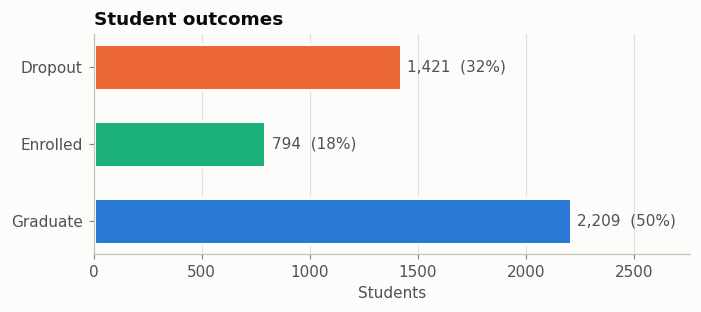

In [2]:
counts = df[config.TARGET].value_counts().reindex(OUTCOME_ORDER)
fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(counts.index, counts.values, color=[OUTCOME_COLORS[o] for o in counts.index],
               height=0.6, edgecolor=SURFACE, linewidth=2)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({n / len(df):.0%})", va="center", color=INK_SECONDARY)
ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Students")
ax.grid(axis="y", visible=False)
ax.set_title("Student outcomes")
save(fig, "01_outcomes")

## 2. Who drops out more?
Dropout rate for students with vs. without each characteristic. The dashed line is the overall rate (32%).

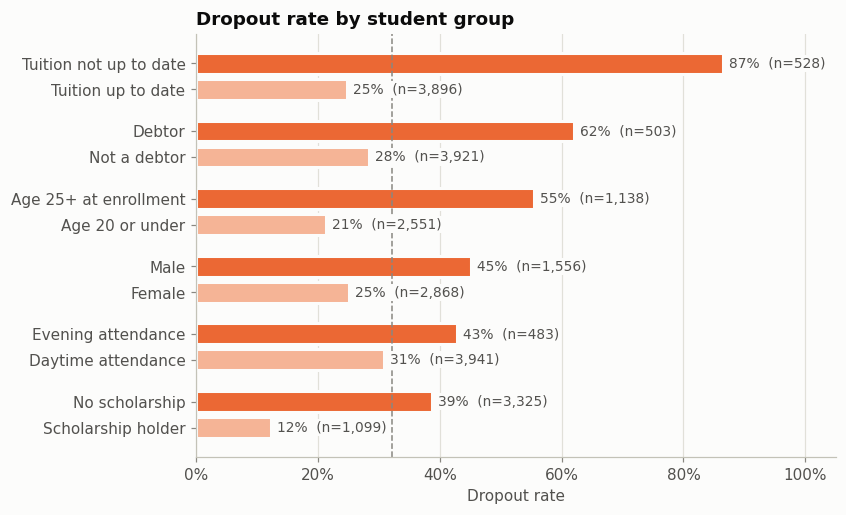

,group,dropout_rate,n
0,Tuition not up to date,0.866,528
1,Tuition up to date,0.247,3896
2,Debtor,0.620,503
3,Not a debtor,0.283,3921
4,Age 25+ at enrollment,0.554,1138
5,Age 20 or under,0.212,2551
6,Male,0.451,1556
7,Female,0.251,2868
8,Evening attendance,0.429,483
9,Daytime attendance,0.308,3941


In [3]:
def rate(mask):
    return is_dropout[mask].mean(), int(mask.sum())

age = df["age_at_enrollment"]
groups = [
    ("Tuition not up to date", df["tuition_up_to_date"] == 0),
    ("Tuition up to date", df["tuition_up_to_date"] == 1),
    ("Debtor", df["debtor"] == 1),
    ("Not a debtor", df["debtor"] == 0),
    ("Age 25+ at enrollment", age >= 25),
    ("Age 20 or under", age <= 20),
    ("Male", df["gender"] == 1),
    ("Female", df["gender"] == 0),
    ("Evening attendance", df["daytime_attendance"] == 0),
    ("Daytime attendance", df["daytime_attendance"] == 1),
    ("No scholarship", df["scholarship_holder"] == 0),
    ("Scholarship holder", df["scholarship_holder"] == 1),
]
table = pd.DataFrame([(name, *rate(m)) for name, m in groups], columns=["group", "dropout_rate", "n"])

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(table)) + np.repeat(np.arange(len(table) // 2) * 0.6, 2)
risky = np.tile([True, False], len(table) // 2)
ax.barh(y, table["dropout_rate"], height=0.8, color=np.where(risky, OUTCOME_COLORS["Dropout"], "#f5b496"),
        edgecolor=SURFACE, linewidth=2)
for yi, r, n in zip(y, table["dropout_rate"], table["n"]):
    ax.text(r + 0.01, yi, f"{r:.0%}  (n={n:,})", va="center", color=INK_SECONDARY, fontsize=9,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(OVERALL, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, table["group"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1.05)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Dropout rate")
ax.set_title("Dropout rate by student group")
save(fig, "02_dropout_by_group")
table.round(3)

Financial status is the strongest single signal: 87% of students behind on tuition drop out. **Open question:** is tuition status really known at enrollment, or recorded later? If later, it belongs in a later stage.

## 3. Dropout rate by course
Course codes are turned into names with the codebook.

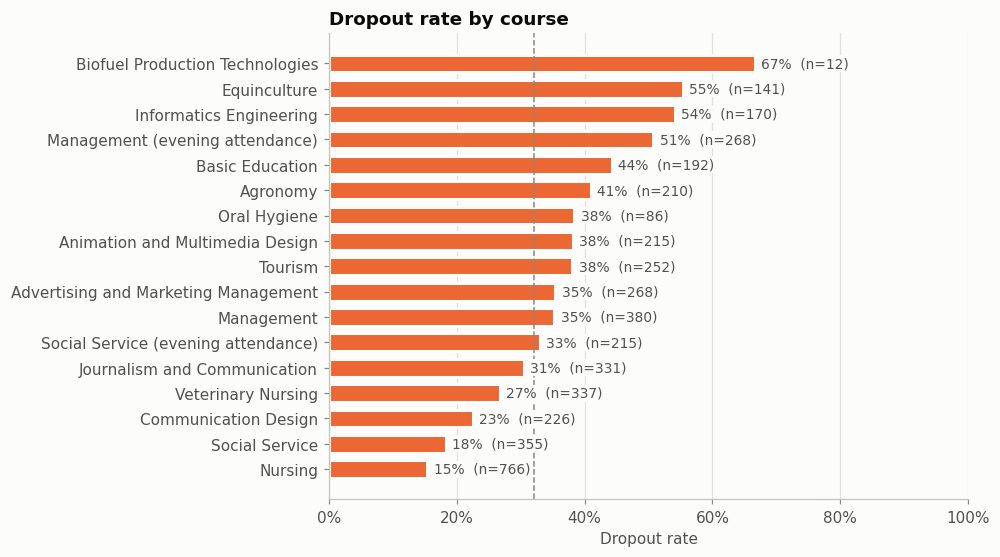

In [4]:
by_course = (decode(df, ["course"]).assign(dropout=is_dropout)
             .groupby("course")["dropout"].agg(rate="mean", n="size")
             .sort_values("rate", ascending=False))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(by_course.index, by_course["rate"], color=OUTCOME_COLORS["Dropout"], height=0.7,
        edgecolor=SURFACE, linewidth=2)
for i, (r, n) in enumerate(zip(by_course["rate"], by_course["n"])):
    ax.text(r + 0.01, i, f"{r:.0%}  (n={n})", va="center", color=INK_SECONDARY, fontsize=9,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(OVERALL, color=MUTED, linestyle="--", linewidth=1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Dropout rate")
ax.set_title("Dropout rate by course")
save(fig, "03_dropout_by_course")

Rates range widely across courses. Some courses are small (Biofuel n=12), so their rates are noisy.

## 4. Grades: entry vs. first semester
Admission grades look almost the same for dropouts and graduates. First-semester grades separate them much more.

*Note:* a recorded grade of 0 means no unit was passed, so those students are left out of the right panel (they are counted in section 5).

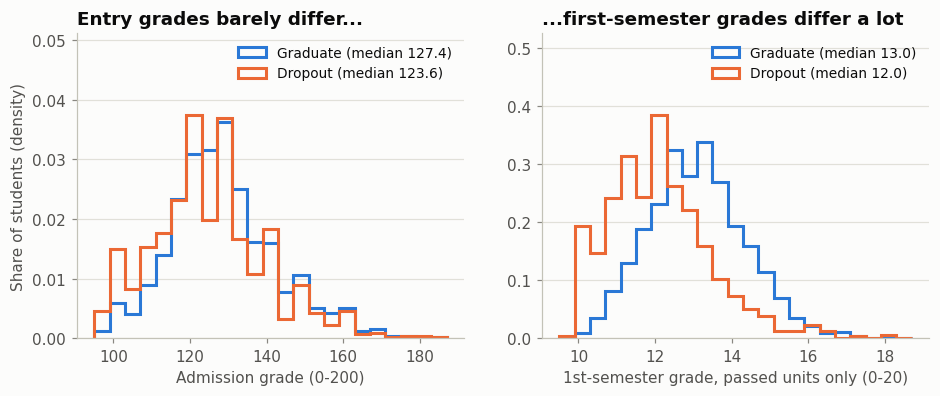

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
panels = [("admission_grade", "Admission grade (0-200)", np.arange(95, 191, 4)),
          ("sem1_grade_real", "1st-semester grade, passed units only (0-20)", np.arange(9.5, 19, 0.4))]
for ax, (col, label, bins) in zip(axes, panels):
    for outcome in ["Graduate", "Dropout"]:
        vals = df.loc[df[config.TARGET] == outcome, col].dropna()
        ax.hist(vals, bins=bins, density=True, histtype="step", linewidth=2,
                color=OUTCOME_COLORS[outcome], label=f"{outcome} (median {vals.median():.1f})")
    ax.set_xlabel(label)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Share of students (density)")
axes[0].set_title("Entry grades barely differ...")
axes[1].set_title("...first-semester grades differ a lot")
save(fig, "04_grades_by_outcome")

## 5. Zero grades and zero units
Two special cases that must not be read literally:
- **Passed none:** enrolled in courses but passed none, so the grade is recorded as 0.
- **No units:** enrolled in 0 courses that semester (e.g. credit transfers). Many of these students still graduate.

In [6]:
cases = {
    "Sem 1: passed none": df["sem1_passed_none"] == 1,
    "Sem 1: no units": df["sem1_no_units"] == 1,
    "Sem 2: passed none": df["sem2_passed_none"] == 1,
    "Sem 2: no units": df["sem2_no_units"] == 1,
}
pd.DataFrame({name: df.loc[m, config.TARGET].value_counts().reindex(OUTCOME_ORDER).fillna(0).astype(int) for name, m in cases.items()}).T.assign(
    total=lambda t: t.sum(axis=1), dropout_share=lambda t: (t["Dropout"] / t["total"]).round(2))

target,Dropout,Enrolled,Graduate,total,dropout_share
Sem 1: passed none,493,43,2,538,0.92
Sem 1: no units,77,28,75,180,0.43
Sem 2: passed none,650,40,0,690,0.94
Sem 2: no units,77,28,75,180,0.43


- Of students who passed nothing in semester 1, 92% dropped out. This is a very strong early signal.
- Of the 180 students with no units, 75 graduated, so "no units" is **not** the same as failing. They get their own flag (`sem1_no_units`) instead.

## 6. First-semester pass rate
The share of enrolled units a student passed in semester 1. Dropout risk falls steeply as the pass rate rises.

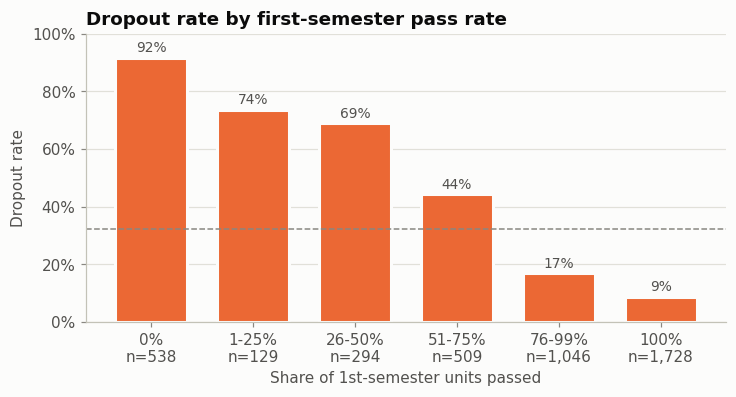

In [7]:
bins = [-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1.0]
labels = ["0%", "1-25%", "26-50%", "51-75%", "76-99%", "100%"]
pr = pd.cut(df["sem1_pass_rate"], bins=bins, labels=labels)
by_pr = is_dropout.groupby(pr, observed=True).agg(rate="mean", n="size")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ticks = [f"{l}\nn={n:,}" for l, n in zip(by_pr.index.astype(str), by_pr["n"])]
ax.bar(ticks, by_pr["rate"], color=OUTCOME_COLORS["Dropout"], width=0.7,
       edgecolor=SURFACE, linewidth=2)
for i, (r, n) in enumerate(zip(by_pr["rate"], by_pr["n"])):
    ax.text(i, r + 0.02, f"{r:.0%}", ha="center", color=INK_SECONDARY, fontsize=9)
ax.axhline(OVERALL, color=MUTED, linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Share of 1st-semester units passed")
ax.set_ylabel("Dropout rate")
ax.set_title("Dropout rate by first-semester pass rate")
save(fig, "05_dropout_by_pass_rate")

## 7. Grade gap: are students doing better or worse than their entry grade predicted?
`sem1_grade_gap` = first-semester grade minus admission grade rescaled to 0-20. Negative means doing worse than their starting point.

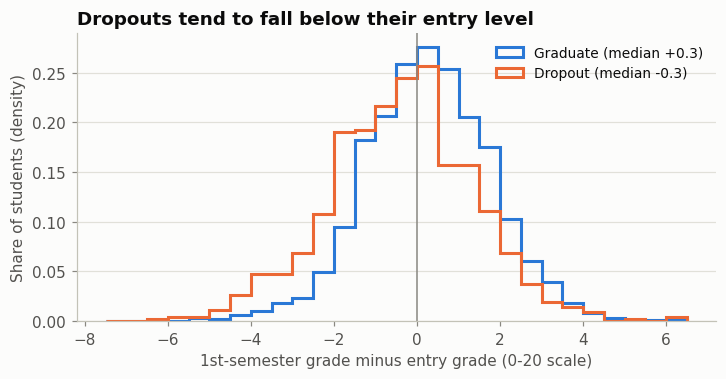

,count,mean,50%
target,,,
Dropout,851.0,-0.41,-0.32
Enrolled,723.0,-0.28,-0.30
Graduate,2132.0,0.26,0.26


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
gap_bins = np.arange(-7.5, 6.6, 0.5)
for outcome in ["Graduate", "Dropout"]:
    vals = df.loc[df[config.TARGET] == outcome, "sem1_grade_gap"].dropna()
    ax.hist(vals, bins=gap_bins, density=True, histtype="step", linewidth=2,
            color=OUTCOME_COLORS[outcome], label=f"{outcome} (median {vals.median():+.1f})")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("1st-semester grade minus entry grade (0-20 scale)")
ax.set_ylabel("Share of students (density)")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9)
ax.set_title("Dropouts tend to fall below their entry level")
save(fig, "06_grade_gap")

df.groupby(config.TARGET)["sem1_grade_gap"].describe()[["count", "mean", "50%"]].round(2)

## 8. The hardest group: passed everything in semester 1, still dropped out

151 of these students dropped out, which is 10.6% of all dropouts.


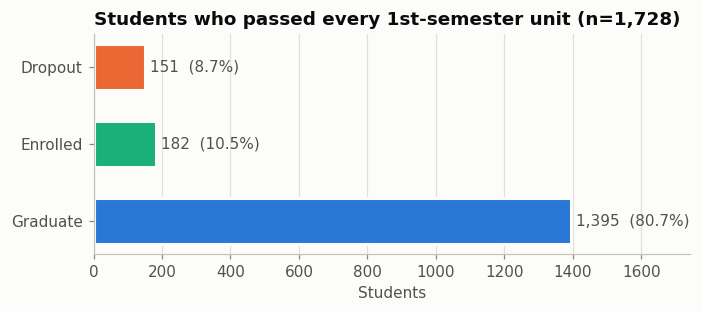

In [9]:
passed_all = df["sem1_passed_all"] == 1
sub = df.loc[passed_all, config.TARGET].value_counts().reindex(OUTCOME_ORDER)

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(sub.index, sub.values, color=[OUTCOME_COLORS[o] for o in sub.index],
               height=0.6, edgecolor=SURFACE, linewidth=2)
for bar, n in zip(bars, sub.values):
    ax.text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2,
            f"{n:,}  ({n / sub.sum():.1%})", va="center", color=INK_SECONDARY)
ax.invert_yaxis()
ax.set_xlim(0, sub.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Students")
ax.set_title(f"Students who passed every 1st-semester unit (n={sub.sum():,})")
save(fig, "07_still_passing_group")

print(f"{sub['Dropout']} of these students dropped out, "
      f"which is {sub['Dropout'] / is_dropout.sum():.1%} of all dropouts.")

Only 9% of this group drop out, so they are rare and hard to spot. Grades alone will not find them, because their grades look fine. This is the group the trajectory features are meant to help with.

## 9. Do the other trajectory features differ by outcome?

In [10]:
traj = ["sem1_pass_rate", "sem2_pass_rate", "sem1_grade_gap", "grade_change", "pass_rate_change", "sem1_eval_rate"]
df.groupby(config.TARGET)[traj].mean().reindex(OUTCOME_ORDER).round(2)

,sem1_pass_rate,sem2_pass_rate,sem1_grade_gap,grade_change,pass_rate_change,sem1_eval_rate
target,,,,,,
Dropout,0.41,0.31,-0.41,-0.08,-0.10,1.35
Enrolled,0.71,0.67,-0.28,-0.07,-0.04,1.60
Graduate,0.93,0.93,0.26,0.04,-0.00,1.25


- Pass rate and grade gap separate dropouts from graduates clearly.
- `grade_change` (semester 1 → 2) is near zero on average for every group. It may still help for individual students, and the models will tell us.
- `eval_rate` counts **exam attempts per enrolled unit**, including retakes, so it can be above 1. It is not an attendance rate, and on its own it barely differs by outcome.

## Summary

1. **Imbalance:** 50% graduate, 32% drop out and 18% are still enrolled, so we report recall and PR-AUC, not just accuracy.
2. **Finances matter most at entry:** 87% of students behind on tuition drop out (vs. 25%). Debtors, older students, men, evening students and non-scholarship students also drop out more.
3. **Course matters:** dropout rates range widely by program.
4. **Entry grades barely predict dropout; first-semester grades and pass rate do.** Students who passed nothing in semester 1 drop out 92% of the time.
5. **Zeros are special:** a 0 grade means nothing was passed, and 0 units is a separate case (many of those students graduate). Both are handled with flags in `features.py`.
6. **Hardest group:** 1,728 students passed every semester-1 unit. 151 of them (9%) still dropped out, about 11% of all dropouts.

**Next:** staged models (enrollment → semester 1 → semester 2), with and without trajectory features.